In [55]:
import pandas as pd
import matplotlib.pyplot as plt
from ipynb.fs.full.preprocessing import process_the_data, read_the_data

<h3> Looking at the steps calculated by DeltabotController

In [80]:
path = "scans/data"
scan = "0020_mesh"
# for x in range(19,39): scans.append(f"000{x}_*")
x_conversion = 0.1/11
y_conversion = x_conversion

start_cx = 294 #px
start_cy = 260 #px
scan_20 = process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy)
scan_20.name = "scan_20"

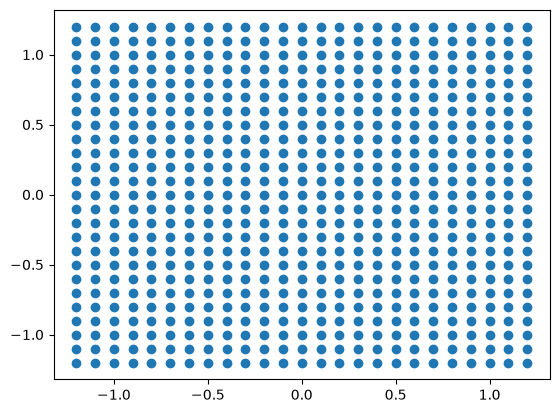

In [ ]:
plt.scatter(scan_20["x"], scan_20["y"]) # the input and the goal

In [51]:
scan_20['sum_motors'] = scan_20["s0"] + scan_20["s1"] + scan_20["s2"]
scan_20['sum_motors']

0      0
1      0
2      0
3      0
4      0
      ..
620    0
621    0
622    0
623    0
624    0
Name: sum_motors, Length: 625, dtype: int64

Text(0.5, 0.98, 'Calculated steps in order')

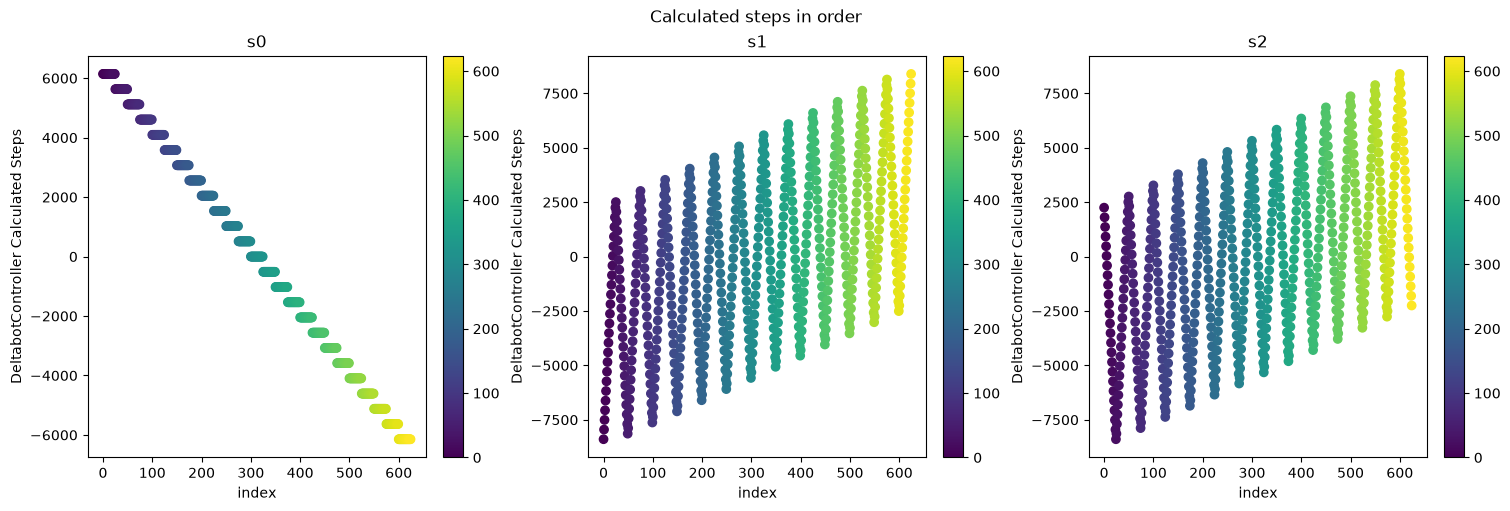

In [38]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(scan_20[motor].index, scan_20[motor], c=scan_20.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("DeltabotController Calculated Steps")
    axs[i].set_title(motor)
    fig.colorbar(im, ax=axs[i])
fig.suptitle("Calculated steps in order")

We can see that the snaking behaviour of the steps

In [17]:
# algorithm_steps
print("Calculated Motor Values Max/Min")
print(max(scan_20["s0"]))
print(max(scan_20["s1"]))
print(max(scan_20["s2"]))
print(min(scan_20["s0"]))
print(min(scan_20["s1"]))
print(min(scan_20["s2"]))

Calculated Motor Values Max/Min
6144
8393
8393
-6144
-8393
-8393


<h3> Looking at the steps predicted by the MLP

In [18]:
#gave those x and y values to the 16Oct MLP 
#output
pred_steps = pd.read_csv("16Oct_NN_Pred_mesh_scan.csv", names=["s0", "s1", "s2"])
display(pred_steps.head())
print("Predicted motor values Max/Min")
print(max(pred_steps["s0"]))
print(max(pred_steps["s1"]))
print(max(pred_steps["s2"]))
print(min(pred_steps["s0"]))
print(min(pred_steps["s1"]))
print(min(pred_steps["s2"]))

,s0,s1,s2
0,-4784.303711,5352.680664,-564.731506
1,-4554.291016,5164.514648,-588.480225
2,-4321.283691,4952.466309,-594.802612
3,-4101.694336,4726.276855,-587.097839
4,-3883.503906,4496.357910,-577.262207


Predicted motor values Max/Min
4090.37109375
5352.6806640625
6623.7626953125
-4900.373046875
-6053.84033203125
-4434.7392578125


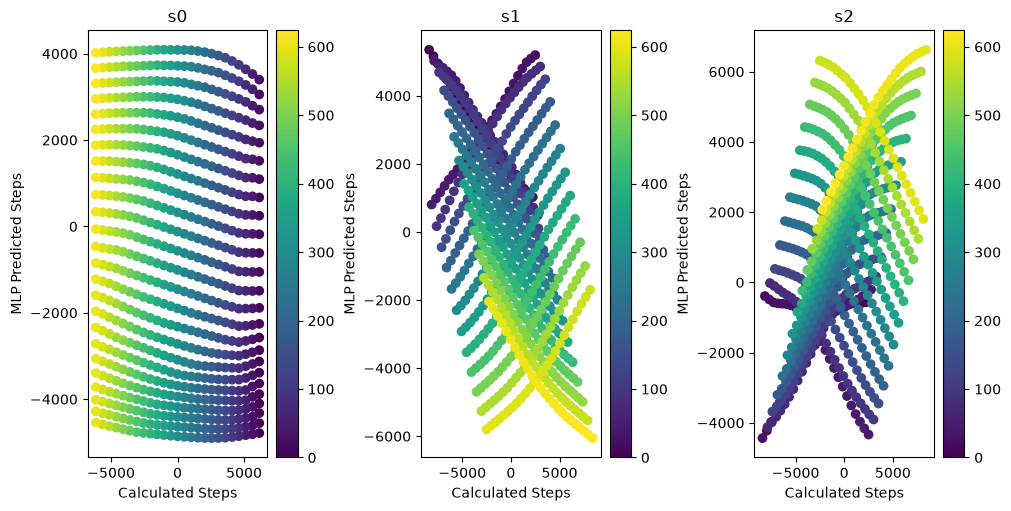

In [30]:
fig, axs = plt.subplots(1, 3, figsize=(10,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(scan_20[motor], pred_steps[motor], c=scan_20["point"])
    axs[i].set_xlabel("Calculated Steps")
    axs[i].set_ylabel("MLP Predicted Steps")
    fig.colorbar(im, ax=axs[i])  
    axs[i].set_title(motor)

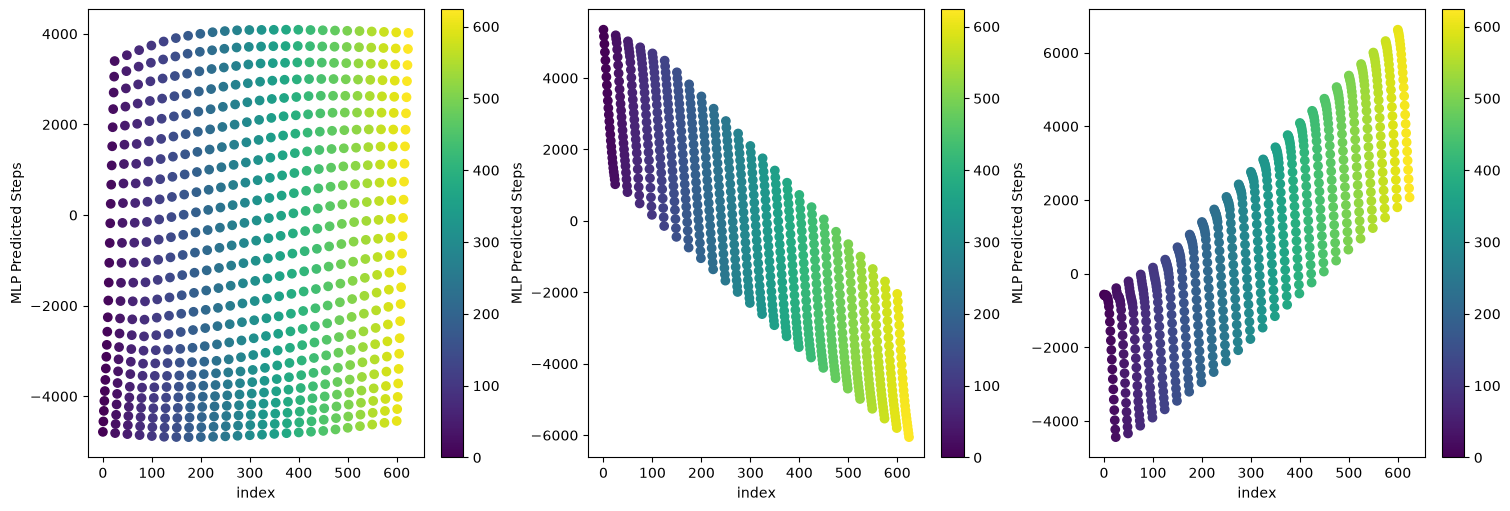

In [35]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(pred_steps[motor].index, pred_steps[motor], c=pred_steps.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("MLP Predicted Steps")
    fig.colorbar(im, ax=axs[i])  

This is going to do the steps in a completely different order - maybe I need to change the order of the steps I gave to the MLP

<h1> Try again with snaking x and y data

In [ ]:
#gave those x and y values to the 16Oct MLP 
#output
pred_snake_steps = pd.read_csv("16Oct_NN_Pred_snake_mesh.csv", names=["s0", "s1", "s2"])
display(pred_snake_steps.head())
print("Predicted motor values Max/Min")
print(max(pred_snake_steps["s0"]))
print(max(pred_snake_steps["s1"]))
print(max(pred_snake_steps["s2"]))
print(min(pred_snake_steps["s0"]))
print(min(pred_snake_steps["s1"]))
print(min(pred_snake_steps["s2"]))

,s0,s1,s2
0,3856.100830,-5897.298828,2016.722412
1,3848.186279,-5617.127930,1746.446533
2,3842.476562,-5336.747559,1473.789795
3,3836.764160,-5056.365234,1201.131104
4,3831.054932,-4775.986328,928.475830


Predicted motor values Max/Min
3856.100830078125
7137.71240234375
6900.59423828125
-5411.97216796875
-5897.298828125
-4365.34326171875


In [ ]:
pred_snake_steps['sum_motors'] = pred_snake_steps["s0"] + pred_snake_steps["s1"] + pred_snake_steps["s2"]
# display(pred_snake_steps['sum_motors'])
print(max(pred_snake_steps["sum_motors"]))
print(min(pred_snake_steps["sum_motors"]))

0     -24.475586
1     -22.495117
2     -20.481201
3     -18.469971
4     -16.455566
         ...    
620   -63.107666
621   -61.257385
622   -58.721924
623   -55.271729
624   -51.297729
Name: sum_motors, Length: 625, dtype: float64

44.611328125
-69.9110107421875


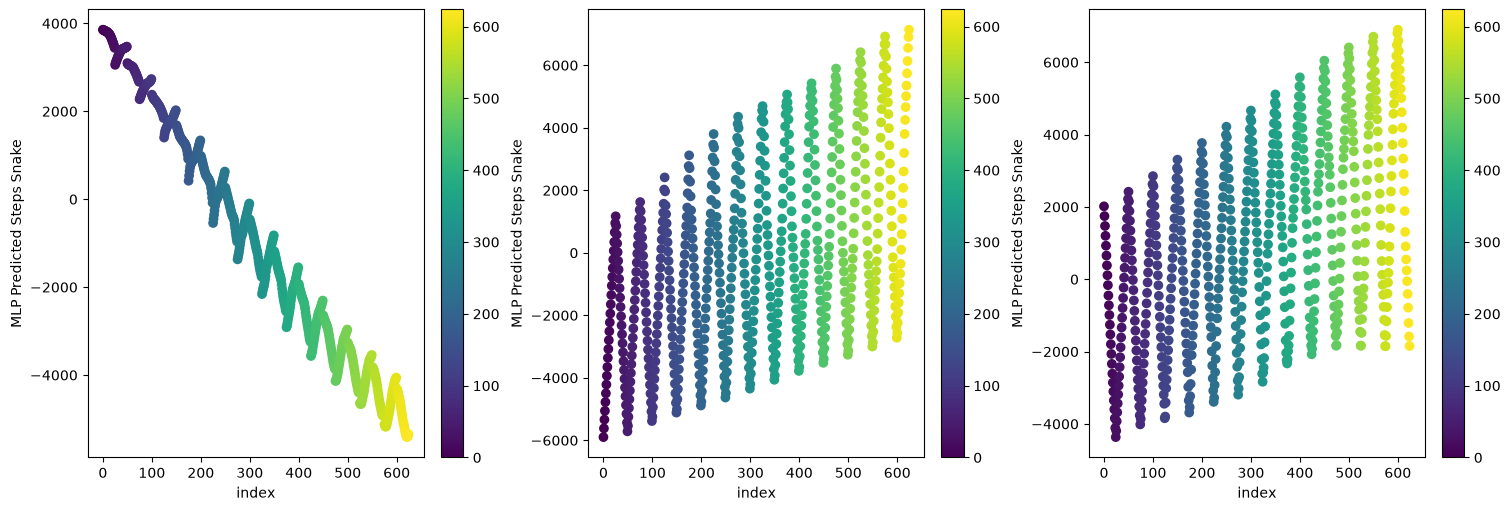

In [41]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(pred_snake_steps[motor].index, pred_snake_steps[motor], c=pred_snake_steps.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("MLP Predicted Steps Snake")
    fig.colorbar(im, ax=axs[i])  

<h2> Comparing the 2 datasets

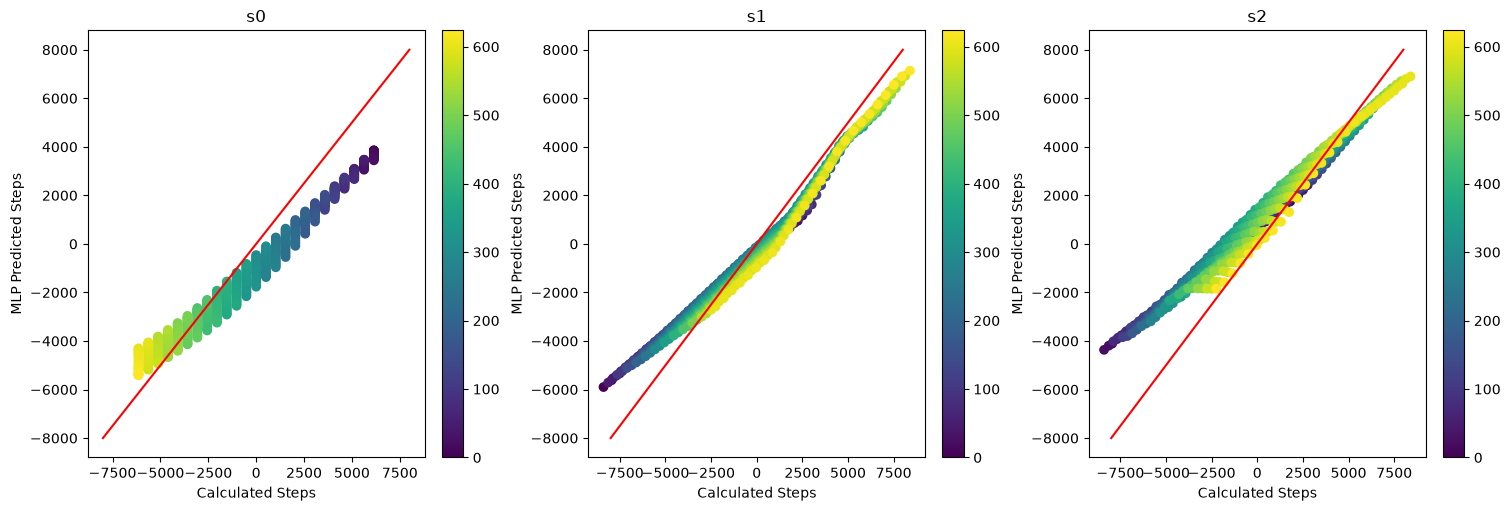

In [45]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(scan_20[motor], pred_snake_steps[motor], c=scan_20["point"])
    axs[i].set_xlabel("Calculated Steps")
    axs[i].set_ylabel("MLP Predicted Steps")
    fig.colorbar(im, ax=axs[i])  
    axs[i].set_title(motor)
    lims = [-8000, 8000]
    # axs[i].set_xlim(lims)
    # axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")

In [87]:
# list(pred_snake_steps.itertuples(index=False, name=None))

<h1>Output from Scan using predicted motor values

In [81]:
path = "scripts/scans/MLP"
scan = "0002_MLP_16Oct"

x_conversion = 0.1/11
y_conversion = x_conversion

start_cx = 298 #px #scan 94
start_cy = 270 #px #scan 94

scan_MLP = process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy)
scan_MLP.name = "scan_MLP"

In [73]:
scan_MLP

,point,time,m0,m1,m2,x_rb,y_rb,s0,s1,s2,...,track_cy,track_radius,roi_x_min,roi_y_min,roi_x_max,roi_y_max,cx_rel,cy_rel,cx_mm,cy_mm
0,0,16.7235,3856,-5897,2017,0.892412,0.754687,3856,-5897,2017,...,154,6,30.0,14.0,310.0,294.0,-128.0,-116.0,1.163636,1.054545
1,1,18.3185,3848,-5617,1746,0.830279,0.753060,3848,-5617,1746,...,154,6,36.0,14.0,316.0,294.0,-122.0,-116.0,1.109091,1.054545
2,2,19.9612,3842,-5337,1474,0.768034,0.751758,3842,-5337,1474,...,156,6,46.0,16.0,326.0,296.0,-112.0,-114.0,1.018182,1.036364
3,3,21.6032,3837,-5056,1201,0.705563,0.750586,3837,-5056,1201,...,158,6,56.0,18.0,336.0,298.0,-102.0,-112.0,0.927273,1.018182
4,4,23.2470,3831,-4776,928,0.643204,0.749349,3831,-4776,928,...,160,6,66.0,20.0,346.0,300.0,-92.0,-110.0,0.836364,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
620,620,1156.8497,-5398,5742,-406,-0.693271,-1.050260,-5398,5742,-406,...,400,6,224.0,260.0,504.0,540.0,66.0,130.0,-0.600000,-1.181818
621,621,1158.7813,-5412,6135,-784,-0.780212,-1.053060,-5412,6135,-784,...,404,6,240.0,264.0,520.0,544.0,82.0,134.0,-0.745455,-1.218182
622,622,1160.7855,-5403,6555,-1210,-0.875610,-1.051497,-5403,6555,-1210,...,406,6,258.0,266.0,538.0,546.0,100.0,136.0,-0.909091,-1.236364
623,623,1162.7225,-5380,6905,-1580,-0.956800,-1.047201,-5380,6905,-1580,...,404,6,272.0,264.0,552.0,544.0,114.0,134.0,-1.036364,-1.218182


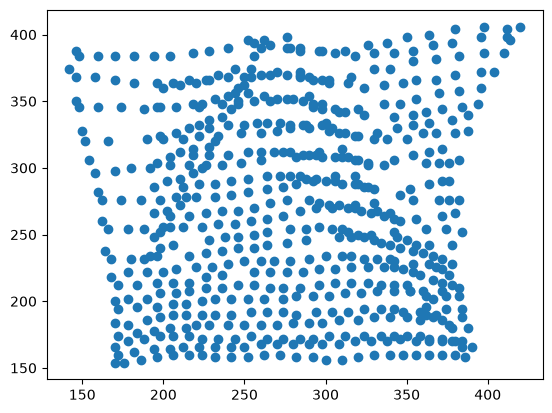

In [74]:
plt.scatter(scan_MLP["cx"], scan_MLP["cy"])

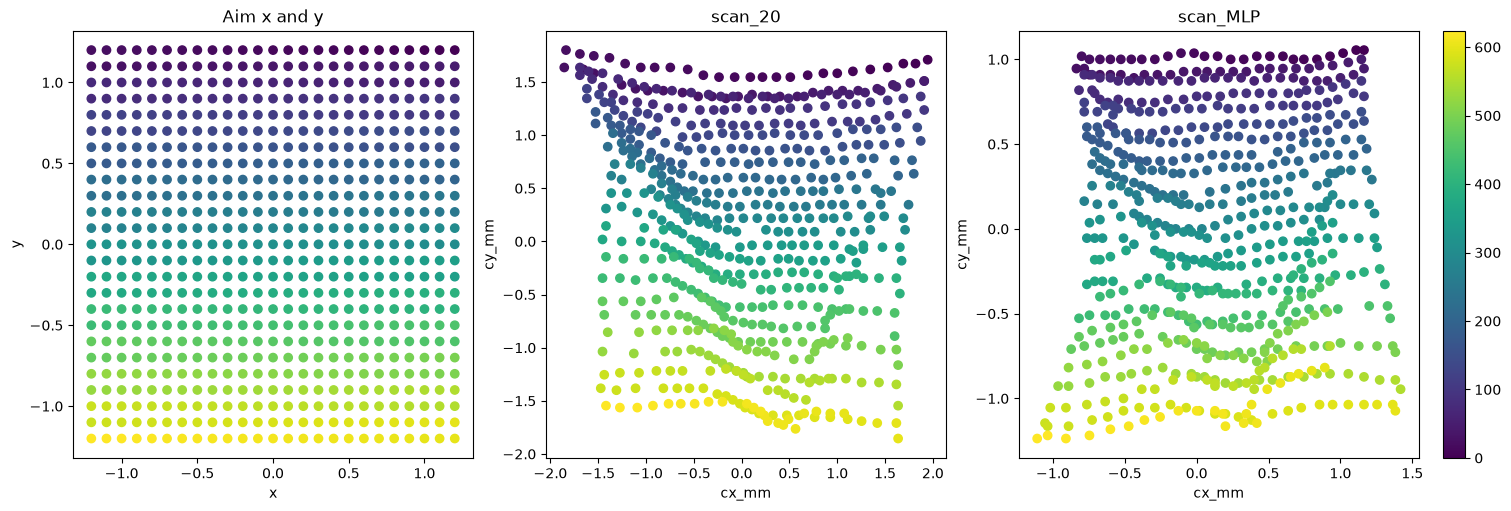

In [86]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)

im = axs[0].scatter(scan_20["x"], scan_20["y"], c=scan_20["point"])
axs[0].set_xlabel("x")
axs[0].set_ylabel("y")
axs[0].set_title("Aim x and y")

i = 1
for scan in scan_20, scan_MLP:
    suplot = axs[i]
    suplot.scatter(scan["cx_mm"], scan["cy_mm"], c=scan["point"])
    suplot.set_xlabel("cx_mm")
    suplot.set_ylabel("cy_mm")
    # fig.colorbar(im, ax=axs[i])  
    suplot.set_title(scan.name)
    i = i+1

fig.colorbar(im, ax=axs[2])  